# Part 1

**Module:** Programming for Data Analytics (PDNA8412)  
**Student:** Katlego Thejane (ST10104762)  
**Institution:** Rosebank College (IIE)

## Executive summary

This study uses the open `goodbooks-10k` book-metadata dataset (10,000 book records) to classify a *high-reader-popularity proxy*. A record is labelled positive when its Goodreads `ratings_count` is at or above the dataset's 90th-percentile threshold. This is **not** a verified commercial sales or publisher bestseller label; the distinction is important when interpreting the results.

Apache Spark is used to load, profile, clean, engineer features and conduct exploratory analysis. The classifier is implemented directly with NumPy batch-gradient descent; Spark is not used to train it. The outcome-defining ratings fields are excluded from the predictors.

## How to run

Keep `goodbooks-10k-books.csv` in the same folder as this notebook. Run the cells from top to bottom. A local Spark runtime requires Java 17 or later. Install the packages before starting Jupyter if required: `pip install pyspark numpy "pandas<3" pyarrow matplotlib seaborn scikit-learn`. The notebook setup cell confirms the installed package versions.


## 1. Dataset evaluation and suitability

The source is the `goodbooks-10k` public repository (Zygmunt, n.d.), whose book metadata file contains exactly 10,000 rows and whose repository states that the wider resource covers six million ratings. The repository is licensed under Creative Commons Attribution-ShareAlike 4.0. The book-level file is large enough to meet the assessment's minimum record requirement and includes publication, language, author, rating and readership metadata.

**Quality and suitability.** The file has 10,000 unique book identifiers and 23 fields. It is structured, readable CSV; key metadata are populated, although publication year and language have missing/invalid values that are explicitly handled below. Ratings and reader counts provide an observable popularity signal. The data are suitable for demonstrating binary classification and Spark-based EDA.

**Important validity boundary.** This is a curated set of the 10,000 Goodreads books with the most ratings, not a representative catalogue of all books and not a source of verified sales rankings. The target is therefore named `high_popularity_proxy` throughout. It supports a methodological demonstration, not a claim that the model predicts commercial bestsellers or will generalise to a publisher's full catalogue.

## 2. Succinct analysis plan

| Stage | Planned work | Decision / evidence |
|---|---|---|
| EDA and cleaning | Inspect schema, row/ID counts, missingness, ranges, skew and class balance; chart key variables by class. | Retain valid book records; impute unusable year to the valid-year median; represent unknown language separately; transform skewed edition count. |
| Feature selection | Use metadata available independently of the label; exclude identifiers, titles, URLs and all ratings-count/distribution fields used to construct the target. | Six interpretable predictors: log edition count, publication year, average rating, author count, English-language indicator and unknown-language indicator. |
| Training | Stratified deterministic 70/15/15 train/validation/test split; standardise using training data only; fit scratch logistic regression with full-batch gradient descent. | Learning rate 0.05; 2,500 iterations; compare L2 penalties 0.01, 0.1 and 1.0 on validation ROC-AUC. |
| Evaluation | Assess ROC-AUC, precision, recall, F1, accuracy and confusion matrix. | Select the decision threshold on validation to maximise F1; report once on the held-out test set. Compare accuracy with the majority-class baseline. |
| Report | Record source, cleaning, EDA, features, scratch implementation, validation choices, test results, limitations and references. | Interpret discrimination and errors in light of class imbalance and the proxy label. |

The split is stratified by class and ordered by a SHA-256 hash of `book_id` within each class. This makes the partition repeatable without relying on the source file's row ordering.


In [1]:
import importlib.metadata as metadata
for package in ("pyspark", "numpy", "pandas", "matplotlib", "seaborn", "scikit-learn"):
    print(f"{package}: {metadata.version(package)}")


pyspark: 4.2.0
numpy: 2.5.3
pandas: 2.3.3
matplotlib: 3.11.2
seaborn: 0.13.2
scikit-learn: 1.9.1


## 3. Imports and reproducibility

The data workflow begins in Spark. NumPy is reserved for the from-scratch classifier, while scikit-learn is used only for standard evaluation metrics, not for model training.


In [2]:
from pathlib import Path
import hashlib
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score
)

DATA_PATH = Path("goodbooks-10k-books.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} is missing. Place the supplied CSV beside this notebook."
    )

spark = (
    SparkSession.builder
    .appName("Part2-Goodreads-Bestseller-Proxy")
    .master("local[*]")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Spark version:", spark.version)
print("Input:", DATA_PATH.resolve())


Spark version: 4.2.0
Input: C:\Users\Katlego.Thejane\.copilot\chats\bf771298-d29b-41a5-8ff1-8b11e79f7a3c\Part2_POE\goodbooks-10k-books.csv


## 4. Load and understand the source

Spark reads the supplied CSV with its header and infers numeric fields. The first checks confirm the expected size, columns, types, and identifier uniqueness before any modelling decisions are made.


In [3]:
raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("multiLine", True)
    .option("escape", '"')
    .csv(str(DATA_PATH))
)

raw.printSchema()
print(f"Source rows: {raw.count():,}")
print(f"Distinct book_id values: {raw.select('book_id').distinct().count():,}")
print("Columns:", raw.columns)
display(raw.limit(5).toPandas())


root
 |-- book_id: integer (nullable = true)
 |-- goodreads_book_id: integer (nullable = true)
 |-- best_book_id: integer (nullable = true)
 |-- work_id: integer (nullable = true)
 |-- books_count: integer (nullable = true)
 |-- isbn: string (nullable = true)
 |-- isbn13: double (nullable = true)
 |-- authors: string (nullable = true)
 |-- original_publication_year: double (nullable = true)
 |-- original_title: string (nullable = true)
 |-- title: string (nullable = true)
 |-- language_code: string (nullable = true)
 |-- average_rating: double (nullable = true)
 |-- ratings_count: integer (nullable = true)
 |-- work_ratings_count: integer (nullable = true)
 |-- work_text_reviews_count: integer (nullable = true)
 |-- ratings_1: integer (nullable = true)
 |-- ratings_2: integer (nullable = true)
 |-- ratings_3: integer (nullable = true)
 |-- ratings_4: integer (nullable = true)
 |-- ratings_5: integer (nullable = true)
 |-- image_url: string (nullable = true)
 |-- small_image_url: string

Source rows: 10,000


Distinct book_id values: 10,000
Columns: ['book_id', 'goodreads_book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


## 5. EDA: data quality, distributions and patterns

Missingness is counted in Spark rather than inferred from a preview. Duplicate book identifiers are removed before analysis. Numeric summaries and class-conditional plots are used to check skew, outliers and whether the selected metadata contain plausible signal. These are descriptive associations, not causal effects.


In [4]:
df = raw.dropDuplicates(["book_id"])
print(f"Rows after de-duplicating book_id: {df.count():,}")

missing_exprs = [
    F.sum(F.col(c).isNull().cast("long")).alias(c)
    for c in ["book_id", "books_count", "authors", "original_publication_year",
              "title", "language_code", "average_rating", "ratings_count"]
]
missing = df.agg(*missing_exprs).toPandas().T.rename(columns={0: "null_count"})
missing["null_percent"] = 100 * missing["null_count"] / df.count()
display(missing)

df.select(
    "books_count", "original_publication_year", "average_rating", "ratings_count"
).describe().show()

print("Missing title:", df.filter(F.col("title").isNull()).count())
print("Missing author:", df.filter(F.col("authors").isNull()).count())


Rows after de-duplicating book_id: 10,000


,null_count,null_percent
book_id,0,0.00
books_count,0,0.00
authors,0,0.00
original_publication_year,21,0.21
title,0,0.00
language_code,1084,10.84
average_rating,0,0.00
ratings_count,0,0.00


+-------+------------------+-------------------------+------------------+------------------+
|summary|       books_count|original_publication_year|    average_rating|     ratings_count|
+-------+------------------+-------------------------+------------------+------------------+
|  count|             10000|                     9979|             10000|             10000|
|   mean|           75.7127|        1981.987674115643| 4.002191000000007|        54001.2351|
| stddev|170.47072765025837|        152.5766651675465|0.2544274805387288|157369.95643554657|
|    min|                 1|                  -1750.0|              2.47|              2716|
|    max|              3455|                   2017.0|              4.82|           4780653|
+-------+------------------+-------------------------+------------------+------------------+



Missing title: 0


Missing author: 0


### EDA interpretation

The source has 10,000 records and 10,000 distinct `book_id` values. In the supplied version, 21 publication-year values are null and 1,084 language values are null; title and author are populated. The ratings-count threshold is deliberately derived from the label source and is shown for understanding the class balance onlyâ€”it is not admitted as a model predictor. The extreme skew in popularity and edition counts makes a plain accuracy score insufficient.


In [5]:
# Use the exact Spark quantile calculation (relativeError=0) to define the
# high-popularity proxy. Ties at the cutoff remain positive.
target_cutoff = float(df.approxQuantile("ratings_count", [0.90], 0.0)[0])
df = df.withColumn(
    "high_popularity_proxy",
    F.when(F.col("ratings_count") >= F.lit(target_cutoff), 1).otherwise(0)
)
print(f"90th-percentile ratings_count cutoff: {target_cutoff:,.0f}")
class_counts = (
    df.groupBy("high_popularity_proxy").count()
    .orderBy("high_popularity_proxy")
)
display(class_counts.toPandas())


90th-percentile ratings_count cutoff: 94,095


,high_popularity_proxy,count
0,0,8999
1,1,1001


### Visual EDA

The log-scaled popularity distribution verifies the long tail and class definition. The following plots compare average rating, publication year and edition-count distributions across the two classes. The rating-count field is used only to define/visualise the outcome; it is excluded from feature engineering.


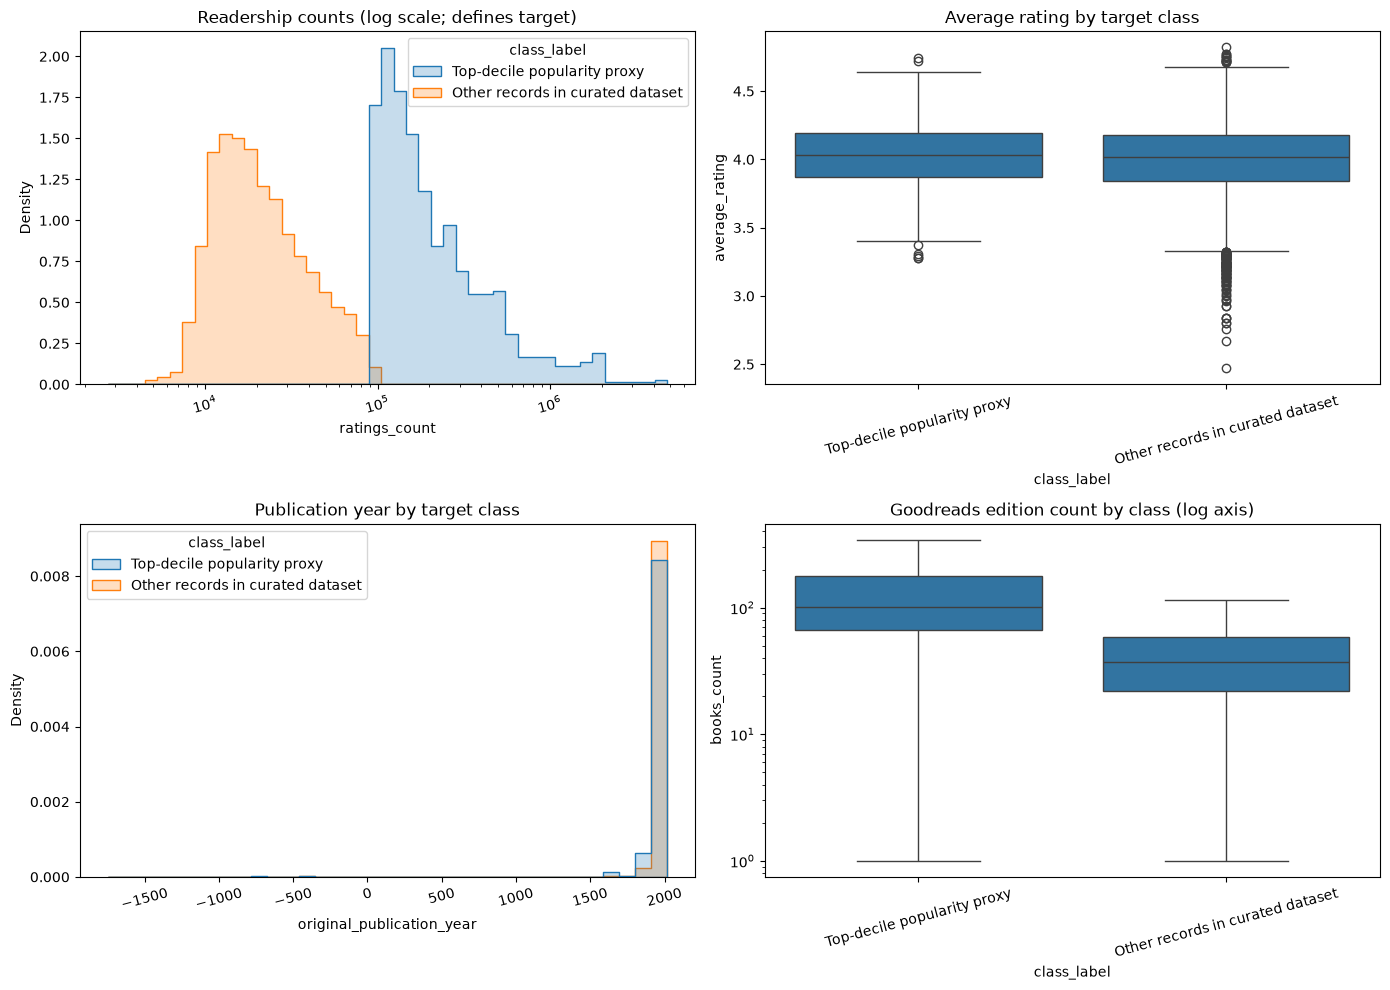

Top language values, including missing:


,language_code,count
0,eng,6341
1,en-US,2070
2,None,1084
3,en-GB,257
4,ara,64
5,en-CA,58
6,fre,25
7,ind,21
8,spa,20
9,ger,13


In [6]:
eda_pd = df.select(
    "high_popularity_proxy", "ratings_count", "average_rating",
    "original_publication_year", "books_count", "language_code"
).toPandas()
eda_pd["class_label"] = eda_pd["high_popularity_proxy"].map(
    {0: "Other records in curated dataset", 1: "Top-decile popularity proxy"}
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(
    data=eda_pd, x="ratings_count", hue="class_label", bins=45,
    log_scale=True, element="step", stat="density", common_norm=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Readership counts (log scale; defines target)")
sns.boxplot(data=eda_pd, x="class_label", y="average_rating", ax=axes[0, 1])
axes[0, 1].set_title("Average rating by target class")
sns.histplot(
    data=eda_pd, x="original_publication_year", hue="class_label",
    bins=35, element="step", stat="density", common_norm=False, ax=axes[1, 0]
)
axes[1, 0].set_title("Publication year by target class")
sns.boxplot(
    data=eda_pd, x="class_label", y="books_count", showfliers=False, ax=axes[1, 1]
)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Goodreads edition count by class (log axis)")
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print("Top language values, including missing:")
display(
    df.groupBy("language_code").count()
    .orderBy(F.desc("count")).limit(12).toPandas()
)


### EDA interpretation and cleaning decisions

In this dataset, the high-popularity proxy has a much higher median `books_count` (102) than the other records (37), while average ratings are similar (approximately 4.03 versus 4.00). The positive group is older on average (about 1978 versus 1992), which cautions against interpreting popularity as a simple function of recency. Edition counts are right-skewed, so their natural logarithm is used. A small number of very early publication-year values are retained rather than silently discarded; null or implausible years outside 1000â€“2020 are imputed to the median valid year.

The language nulls are not treated as non-English. Two separate binary indicators preserve the distinction between English and unknown language; known non-English is represented by both indicators being zero.


## 6. Feature selection, leakage control and preparation

Feature selection is based on target provenance, interpretability, and data availability at the point a book might be assessedâ€”not on p-values. `ratings_count`, `work_ratings_count`, `work_text_reviews_count`, and the one-to-five rating totals are excluded because they directly measure the reader activity that defines or closely reproduces the target. IDs, title, author names, ISBNs, and image URLs are excluded as identifiers, high-cardinality fields, or non-numeric text.

| Predictor | Rationale |
|---|---|
| `log_books_count` | Log-scaled edition-listing count; the EDA showed a class difference and strong right skew. |
| `publication_year` | Publication context / recency, with invalid values imputed using the valid-year median. |
| `average_rating` | Mean reader evaluation; distinct from the count-based target, though measured contemporaneously. |
| `author_count` | Small, interpretable authorship-composition feature. |
| `is_english` | Captures whether a known language code begins with `en`. |
| `language_unknown` | Retains missing-language information without conflating it with non-English. |

All scaling parameters are estimated on training records only. The data are not randomly re-ordered by source row; a class-stratified hash split avoids relying on the repository's ordering.


In [7]:
# Clean the year field, impute the median of valid years, and engineer
# interpretable numeric predictors in Spark.
year_numeric = F.col("original_publication_year").cast(DoubleType())
df = df.withColumn(
    "publication_year_clean",
    F.when((year_numeric >= 1000) & (year_numeric <= 2020), year_numeric)
)
valid_year_median = float(
    df.approxQuantile("publication_year_clean", [0.50], 0.0)[0]
)
language = F.lower(F.trim(F.col("language_code")))

prepared = (
    df.withColumn(
        "publication_year",
        F.coalesce(F.col("publication_year_clean"), F.lit(valid_year_median))
    )
    .withColumn(
        "log_books_count",
        F.log(F.col("books_count").cast("double") + F.lit(1.0))
    )
    .withColumn("author_count", F.size(F.split(F.col("authors"), r"\s*,\s*")).cast("double"))
    .withColumn(
        "is_english",
        F.when(language.startswith("en"), 1.0).otherwise(0.0)
    )
    .withColumn(
        "language_unknown",
        F.when(F.col("language_code").isNull() | (F.trim(F.col("language_code")) == ""), 1.0)
         .otherwise(0.0)
    )
    .withColumn("average_rating", F.col("average_rating").cast("double"))
)

feature_columns = [
    "log_books_count", "publication_year", "average_rating",
    "author_count", "is_english", "language_unknown"
]
model_pd = (
    prepared.select("book_id", *feature_columns, "high_popularity_proxy")
    .orderBy("book_id")
    .toPandas()
)
if model_pd[feature_columns + ["high_popularity_proxy"]].isna().any().any():
    raise ValueError("Unexpected null remains in model features or target.")

print(f"Valid-year median used for imputation: {valid_year_median:.0f}")
print(f"Prepared modelling rows: {len(model_pd):,}")
print("Feature columns:", feature_columns)
display(model_pd.head())


Valid-year median used for imputation: 2004
Prepared modelling rows: 10,000
Feature columns: ['log_books_count', 'publication_year', 'average_rating', 'author_count', 'is_english', 'language_unknown']


,book_id,log_books_count,publication_year,average_rating,author_count,is_english,language_unknown,high_popularity_proxy
0,1,5.609472,2008.0,4.34,1.0,1.0,0.0,1
1,2,6.198479,1997.0,4.44,2.0,1.0,0.0,1
2,3,5.424950,2005.0,3.57,1.0,1.0,0.0,1
3,4,6.190315,1960.0,4.25,1.0,1.0,0.0,1
4,5,7.213032,1925.0,3.89,1.0,1.0,0.0,1


## 7. Additional EDA: predictor relationships

The correlation matrix is a screening diagnostic for redundant numeric predictors, not a causal analysis or an automatic feature selector. The model is regularised and the chosen predictors remain interpretable. In particular, the target-generation fields do not appear in this matrix.


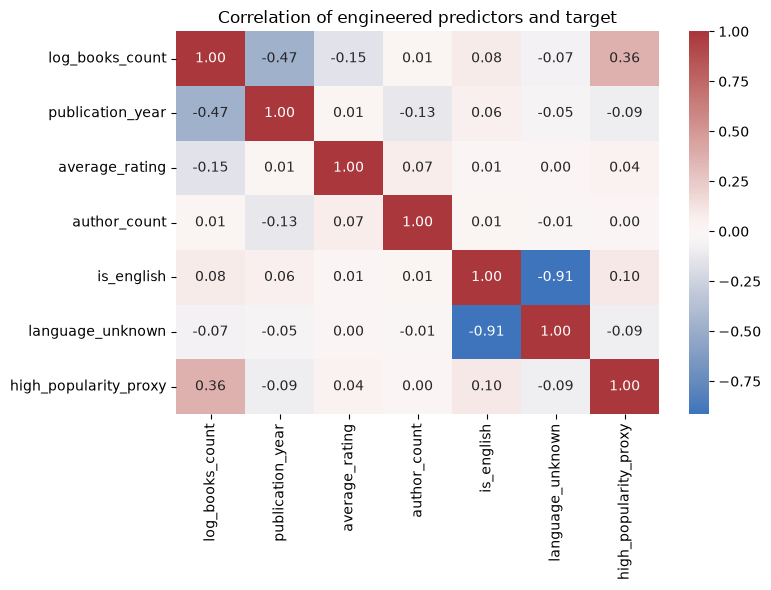

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    model_pd[feature_columns + ["high_popularity_proxy"]].corr(numeric_only=True),
    annot=True, fmt=".2f", cmap="vlag", center=0
)
plt.title("Correlation of engineered predictors and target")
plt.tight_layout()
plt.show()


## 8. Deterministic stratified train/validation/test split

The validation set is used for penalty and threshold selection. The test set is held back until the final evaluation. Sorting each class by the SHA-256 digest of its book identifier gives a reproducible pseudo-random ordering; it also prevents the popularity-ranked source order from becoming the split rule.


In [9]:
y_all = model_pd["high_popularity_proxy"].to_numpy(dtype=int)
hash_keys = model_pd["book_id"].astype(str).map(
    lambda value: hashlib.sha256(value.encode("utf-8")).hexdigest()
)

train_idx, val_idx, test_idx = [], [], []
for class_value in (0, 1):
    class_indices = model_pd.index[y_all == class_value].tolist()
    class_indices.sort(key=lambda idx: hash_keys.iloc[idx])
    n_train = math.floor(0.70 * len(class_indices))
    n_val = math.floor(0.15 * len(class_indices))
    train_idx.extend(class_indices[:n_train])
    val_idx.extend(class_indices[n_train:n_train + n_val])
    test_idx.extend(class_indices[n_train + n_val:])

train_idx = np.asarray(train_idx, dtype=int)
val_idx = np.asarray(val_idx, dtype=int)
test_idx = np.asarray(test_idx, dtype=int)
print("Split sizes:", len(train_idx), len(val_idx), len(test_idx))
print("Positive counts:", y_all[train_idx].sum(), y_all[val_idx].sum(), y_all[test_idx].sum())


Split sizes: 6999 1499 1502
Positive counts: 700 150 151


## 9. Logistic regression implemented from scratch

For an input vector \(x\), the model estimates \(p(y=1|x)=\sigma(w_0+x^T w)\), where \(\sigma(z)=1/(1+e^{-z})\). Parameters are learned by batch gradient descent on binary cross-entropy with an L2 penalty on coefficients (not the intercept). The gradient is computed directly with NumPy; no machine-learning estimator is used to fit the model.

The predictors are standardised using only training-set means and standard deviations. A numerically clipped sigmoid prevents overflow. Three penalty strengths are compared on validation ROC-AUC; the decision threshold is separately chosen to maximise validation F1 because the positive class is only about one tenth of the sample.


In [10]:
X_raw = model_pd[feature_columns].to_numpy(dtype=float)
X_train_raw = X_raw[train_idx]
feature_mean = X_train_raw.mean(axis=0)
feature_scale = X_train_raw.std(axis=0)
feature_scale[feature_scale == 0] = 1.0

X_all = np.column_stack([
    np.ones(len(X_raw)),
    (X_raw - feature_mean) / feature_scale
])

def sigmoid(z):
    z = np.clip(z, -35.0, 35.0)
    return 1.0 / (1.0 + np.exp(-z))

def fit_logistic_gd(X, y, indices, l2=0.01, learning_rate=0.05, iterations=2500):
    """Fit binary logistic regression by full-batch gradient descent."""
    weights = np.zeros(X.shape[1], dtype=float)
    X_part = X[indices]
    y_part = y[indices].astype(float)
    n = len(indices)

    for _ in range(iterations):
        probabilities = sigmoid(X_part @ weights)
        gradient = (X_part.T @ (probabilities - y_part)) / n
        gradient[1:] += l2 * weights[1:]  # Do not penalise the intercept.
        weights -= learning_rate * gradient
    return weights

def predict_probability(X, weights):
    return sigmoid(X @ weights)

def best_f1_threshold(y_true, probabilities):
    """Choose a probability threshold on validation data, never on test data."""
    best_threshold, best_f1 = 0.5, -1.0
    for threshold in np.unique(probabilities):
        predictions = (probabilities >= threshold).astype(int)
        score = f1_score(y_true, predictions, zero_division=0)
        if score > best_f1:
            best_threshold, best_f1 = float(threshold), float(score)
    return best_threshold, best_f1


## 10. Hyperparameter comparison and validation threshold

L2 regularisation limits coefficient size and helps reduce overfitting. The penalty is selected using validation ROC-AUC, which is threshold-independent. F1 is used to select an operating threshold because missing all positives would make an accuracy-only model appear deceptively successful in an imbalanced dataset.


In [11]:
from sklearn.metrics import f1_score

validation_results = []
selected = None
for penalty in (0.01, 0.1, 1.0):
    candidate_weights = fit_logistic_gd(
        X_all, y_all, train_idx, l2=penalty,
        learning_rate=0.05, iterations=2500
    )
    val_probability = predict_probability(X_all[val_idx], candidate_weights)
    val_auc = roc_auc_score(y_all[val_idx], val_probability)
    threshold, val_f1 = best_f1_threshold(y_all[val_idx], val_probability)
    validation_results.append({
        "L2 penalty": penalty,
        "Validation ROC-AUC": val_auc,
        "Validation F1 at selected threshold": val_f1,
        "Threshold": threshold
    })
    if selected is None or val_auc > selected["auc"]:
        selected = {
            "penalty": penalty, "weights": candidate_weights,
            "auc": val_auc, "threshold": threshold, "val_f1": val_f1
        }

display(pd.DataFrame(validation_results))
print("Selected penalty:", selected["penalty"])
print("Validation-selected threshold:", selected["threshold"])


,L2 penalty,Validation ROC-AUC,Validation F1 at selected threshold,Threshold
0,0.01,0.871109,0.521994,0.185662
1,0.10,0.863044,0.500000,0.140815
2,1.00,0.850131,0.469974,0.107753


Selected penalty: 0.01
Validation-selected threshold: 0.1856618041173069


## 11. Final held-out evaluation

The test set is evaluated once with the selected validation penalty and threshold. ROC-AUC measures ranking ability across thresholds; precision measures the reliability of flagged records; recall measures the positive cases found; F1 balances precision and recall. Accuracy is reported, but compared with a majority-class baseline and not treated as the sole measure.


,Held-out result
Test records,1502.000000
ROC-AUC,0.835307
Accuracy,0.869507
Precision,0.395349
Recall,0.562914
F1,0.464481
Threshold,0.185662
Majority-class accuracy baseline,0.899467


Confusion matrix [[TN, FP], [FN, TP]] = [[1221, 130], [66, 85]]


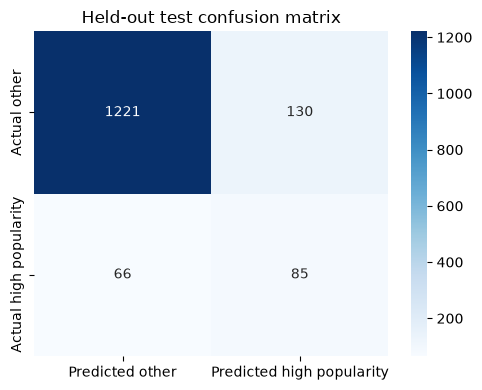

In [12]:
test_probability = predict_probability(X_all[test_idx], selected["weights"])
test_prediction = (test_probability >= selected["threshold"]).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_all[test_idx], test_prediction, labels=[0, 1]
).ravel()
test_metrics = {
    "Test records": len(test_idx),
    "ROC-AUC": roc_auc_score(y_all[test_idx], test_probability),
    "Accuracy": accuracy_score(y_all[test_idx], test_prediction),
    "Precision": precision_score(y_all[test_idx], test_prediction, zero_division=0),
    "Recall": recall_score(y_all[test_idx], test_prediction, zero_division=0),
    "F1": f1_score(y_all[test_idx], test_prediction, zero_division=0),
    "Threshold": selected["threshold"],
    "Majority-class accuracy baseline": max(
        np.mean(y_all[test_idx] == 0), np.mean(y_all[test_idx] == 1)
    )
}
display(pd.Series(test_metrics, name="Held-out result").to_frame())
print(f"Confusion matrix [[TN, FP], [FN, TP]] = [[{tn}, {fp}], [{fn}, {tp}]]")

plt.figure(figsize=(5, 4))
sns.heatmap(
    np.array([[tn, fp], [fn, tp]]), annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted other", "Predicted high popularity"],
    yticklabels=["Actual other", "Actual high popularity"]
)
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()


### Interpretation and retraining decision

The report records the validation comparison and the held-out metrics generated by these cells. A higher regularisation penalty is not assumed to be better: the validation comparison determines whether it improves ranking. A threshold below 0.5 is justified only when the validation F1 gain supports a recall-oriented operating point. If the held-out confusion matrix shows material false positives or false negatives, the appropriate conclusion is to restrict the model to prioritisation and gather verified sales outcomesâ€”not to tune against the test set.

The test ROC-AUC and F1 should be interpreted together. Accuracy can be lower than the all-negative baseline because the selected threshold deliberately identifies positive cases. The model is therefore not judged by accuracy alone.


In [13]:
coefficient_table = pd.DataFrame({
    "Feature": ["Intercept"] + feature_columns,
    "Standardised coefficient": selected["weights"]
})
display(coefficient_table)
print(
    "Positive coefficients increase the fitted log-odds conditional on the other "
    "included predictors; they are associations, not causal effects."
)


,Feature,Standardised coefficient
0,Intercept,-2.754482
1,log_books_count,1.370033
2,publication_year,0.427032
3,average_rating,0.304435
4,author_count,-0.178950
5,is_english,0.252543
6,language_unknown,-0.147679


Positive coefficients increase the fitted log-odds conditional on the other included predictors; they are associations, not causal effects.


## 12. Conclusion, limitations and responsible use

The workflow demonstrates Spark-based EDA and feature preparation alongside a logistic-regression learner implemented from first principles. It provides a transparent, reproducible binary classifier and evaluates it on held-out records with imbalance-aware metrics.

The principal limitation is label validity: Goodreads ratings count is a measure of platform readership, not verified units sold, and the source itself is restricted to the 10,000 most-rated books. Average rating is also measured contemporaneously with popularity, so the study is retrospective classification rather than a genuine forecast made before launch. Coverage and language missingness can create selection bias. A production-grade press decision requires a much broader catalogue and independently verified, time-stamped sales/rank labels; only information available before the prediction date should be used.

**Client recommendation:** treat the result as an exploratory ranking aid for further review, not an automated bestseller decision. The next study should evaluate on a temporal holdout and an external set containing both popular and non-popular titles.

## References

Apache Spark (n.d.) *PySpark documentation*. Available at: https://spark.apache.org/docs/latest/api/python/ (Accessed: 6 October 2026).

Hosmer, D.W., Lemeshow, S. and Sturdivant, R.X. (2013) *Applied Logistic Regression*. 3rd edn. Hoboken, NJ: Wiley.

Harris, C.R. et al. (2020) â€˜Array programming with NumPyâ€™, *Nature*, 585, pp. 357â€“362. doi: 10.1038/s41586-020-2649-2.

Pedregosa, F. et al. (2011) â€˜Scikit-learn: Machine Learning in Pythonâ€™, *Journal of Machine Learning Research*, 12, pp. 2825â€“2830.

Zygmunt (n.d.) *goodbooks-10k: Books, ratings, tags and related files* [Data set]. GitHub. Available at: https://github.com/zygmuntz/goodbooks-10k (Accessed: 6 October 2026). Licensed under CC BY-SA 4.0.

Zou, H. and Hastie, T. (2005) â€˜Regularization and variable selection via the elastic netâ€™, *Journal of the Royal Statistical Society: Series B*, 67(2), pp. 301â€“320.
